## Predict the diffusivity w.r.t Temperature, $D(T)$

In [1]:
import numpy as np
import torch
from torch import nn
import torchvision
import matplotlib.pyplot as plt
%matplotlib inline
from torch.utils.tensorboard import SummaryWriter
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, TensorDataset
import datetime

In [2]:
diff_T = np.loadtxt('getDiffData/diffCons_T.txt')
T = diff_T[:,0]
D_0 = 0.5*diff_T[:,1]
T_trch = torch.from_numpy(T)
D_true = torch.from_numpy(D_0)

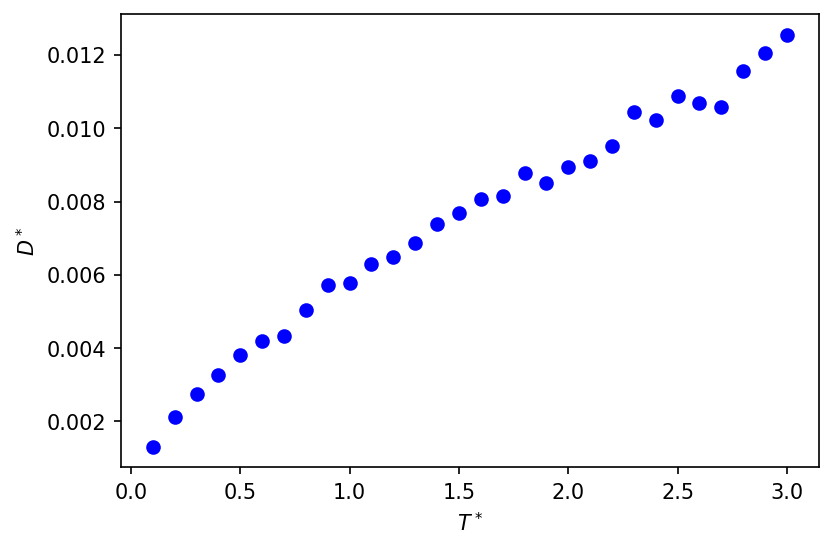

In [11]:
fig_id = 1
plt.figure(fig_id)
plt.plot(T, D_0, 'bo')
plt.xlabel('$T^*$')
plt.ylabel('$D^*$')
plt.show()
fig_id += 1

In [4]:
class ffnn(nn.Module):
    """basic FF network for approximating functions"""
    def __init__(self, nn_width=10, num_hidden=1):
        super().__init__()
        
        self.layer_first = nn.Linear(1, nn_width)
        
        layers = []
        for _ in range(num_hidden):
            layers.append(nn.Linear(nn_width, nn_width))
        self.layer_hidden = nn.ModuleList(layers)
        
        self.layer_last = nn.Linear(nn_width, 1)
        
    def forward(self, x):
        activation = nn.Tanh()
        u = activation(self.layer_first(x))
        for hidden in self.layer_hidden:
            u = activation(hidden(u))
        u = self.layer_last(u)
        return u

In [5]:
def loss_function(model,x):

    d_p = model(x.float())
    loss = torch.pow(D_true - d_p, 2).mean()
    return 1000*loss

In [6]:
model = ffnn()

lr = 0.01
n_epochs = 5000
opt = torch.optim.Adam(model.parameters(), lr)

loss_history = []



In [7]:
print(D_true.shape)
print(T_trch.shape)
D_true = D_true.reshape(len(D_true),1)
T_trch = T_trch.reshape(len(T_trch),1)
print(D_true.shape)
print(T_trch.shape)

torch.Size([30])
torch.Size([30])
torch.Size([30, 1])
torch.Size([30, 1])


In [8]:
for i in range(n_epochs):
    loss_i = loss_function(model,T_trch)
    opt.zero_grad()
    loss_history.append(loss_i.item())
    loss_i.backward()
    opt.step()
    
    if i % 100 == 0 or i == n_epochs-1:
        print(f'epoch {i}, loss = {loss_i}')

epoch 0, loss = 364.27953966288965
epoch 100, loss = 0.04423155121942571
epoch 200, loss = 0.025636317505872742
epoch 300, loss = 0.013399115871788594
epoch 400, loss = 0.006484643185019875
epoch 500, loss = 0.0029368970263713356
epoch 600, loss = 0.0012533599689394676
epoch 700, loss = 0.0005149394127888056
epoch 800, loss = 0.00021741077891256145
epoch 900, loss = 0.00010801387002602943
epoch 1000, loss = 7.14751447382897e-05
epoch 1100, loss = 6.038129325281108e-05
epoch 1200, loss = 5.7251350629369375e-05
epoch 1300, loss = 5.634696428569407e-05
epoch 1400, loss = 5.599632969895794e-05
epoch 1500, loss = 5.576821716563414e-05
epoch 1600, loss = 5.556605885482753e-05
epoch 1700, loss = 5.536691733529205e-05
epoch 1800, loss = 5.517656058449256e-05
epoch 1900, loss = 5.4989412427644e-05
epoch 2000, loss = 5.4810875046331874e-05
epoch 2100, loss = 5.463357347650643e-05
epoch 2200, loss = 5.4469336758119596e-05
epoch 2300, loss = 5.4306877500577936e-05
epoch 2400, loss = 5.415709769136

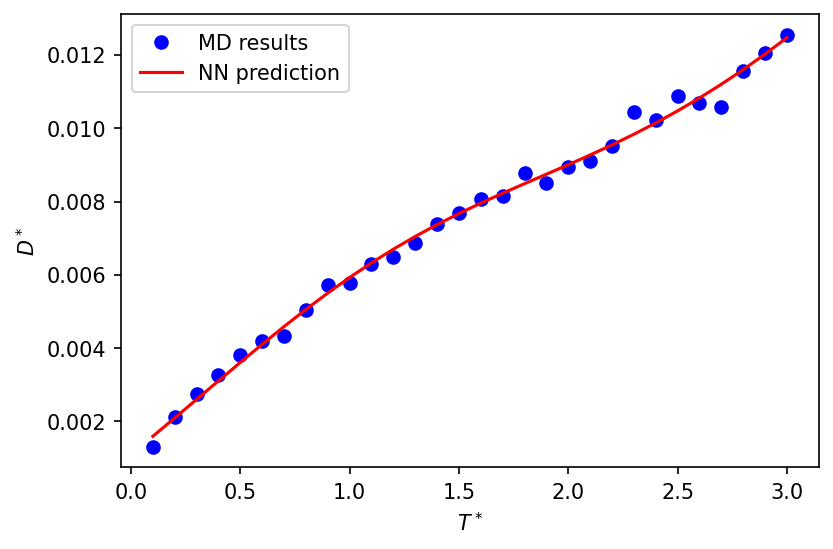

In [10]:
d_p = model(T_trch.float())
plt.figure(fig_id)
plt.rcParams['figure.dpi'] = 150 
plt.plot(T, D_0, 'bo',label = 'MD results')
plt.plot(T, d_p.detach().numpy(), 'r', label = 'NN prediction')
plt.xlabel('$T^*$')
plt.ylabel('$D^*$')
plt.legend()
plt.show()
fig_id += 1

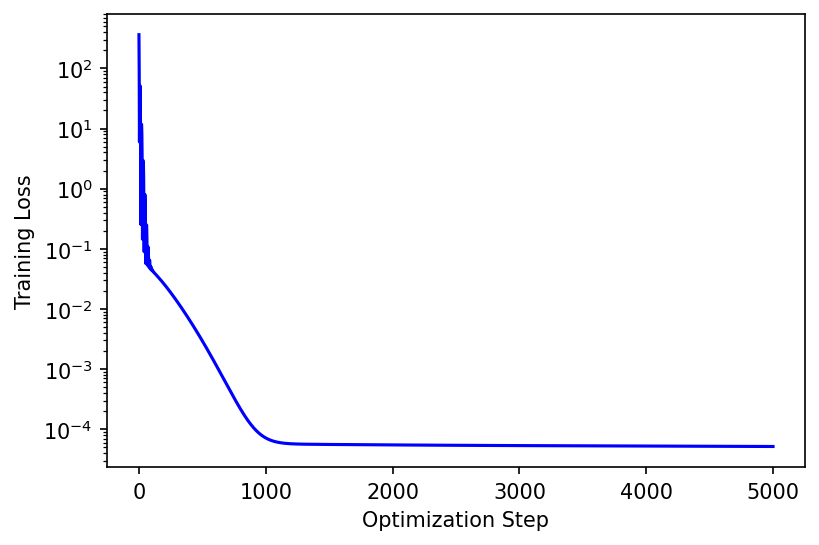

In [12]:
plt.semilogy(loss_history,'b')

plt.xlabel('Optimization Step')
plt.ylabel('Training Loss')
plt.show()